# Abalone Case Study

## Problem Statement:
The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- a boring and time-consuming task. Other measurements, which are easier to obtain, are used to predict the age. Further information, such as weather patterns and location (hence food availability) may be required to solve the problem.

### Attribute Information

Given is the attribute name, attribute type, the measurement unit and a brief description.
The number of rings is the value to predict. 

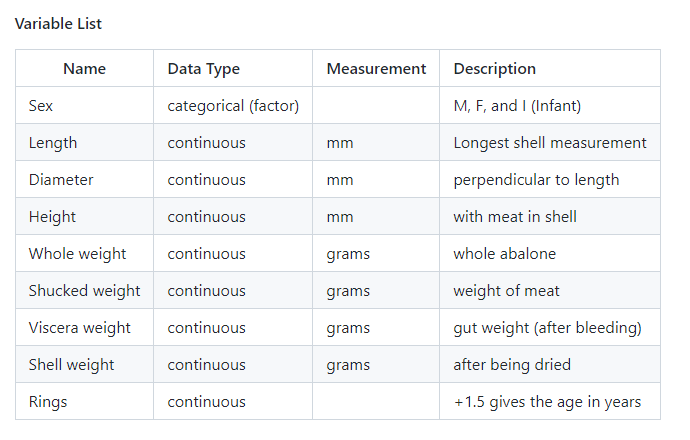

Downlaod Files:
https://github.com/dsrscientist/dataset1/blob/master/abalone.csv

---------------------------------------------------------------------------------------------------------------------------

# Objective :

To predict the number of  rings in each abalone which will lead us to the age of that abalone.

The age of abalone is ( number of rings +1.5) years.

---------------------------------------------------------------------------------------------------------------------------

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

In [86]:
df =pd.read_csv('abalone.csv')

In [87]:
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


--------------------------------------------------------------------------------------------------------------------------

# Statistical Summary

In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [89]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [90]:
df['Sex'].value_counts()

M    1528
I    1342
F    1307
Name: Sex, dtype: int64

<AxesSubplot:xlabel='Sex', ylabel='count'>

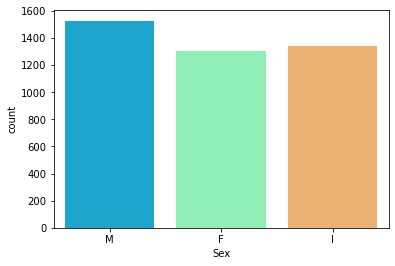

In [91]:
sns.countplot(df['Sex'], palette='rainbow')

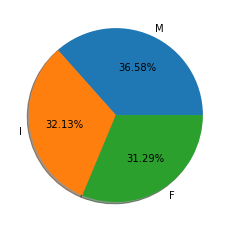

In [92]:
labels = 'M','I','F'
fig, ax = plt.subplots()
ax.pie(df['Sex'].value_counts(),labels = labels,radius =1,autopct = '%1.2f%%', shadow=True,)
plt.show()

#### Comment :

1. Minimum of ring is 1 and maximum number of rings is 29.
2. There is lot of difference between 3rd quartile and maximum value in height, whole weight and shucked weight.So there is possibilty of outliers in these columns.
3. By taking consideration of mean and std deviation columns in staticscal summary we can see that spread of distribution is large in case of whole weight and Rings columns.
4. Average number of rings in abalone is 9. So in further investiagtion we need to range of number in case of adult abalone and infant abalone.
5. Sex is categorical data having object datatypes need to convert into numerical datatypes using encoding techniques.
6. From Max row we can say that there is possibilty that abalone having higher height, whole weight, shucked weight and higher number of rings. So inturn investigating relation between age and aspects like weight, height.
7. In dataset we have 4177 entries with 9 features.
8. Sex has three unique categories Male, Female and infant.
9. None of the features have minimum = 0 except Height. (need to look in)

In [93]:
missing_values = df.isnull().sum().sort_values(ascending = False)
percentage_missing_values =(missing_values/len(df))*100
print(pd.concat([missing_values, percentage_missing_values], axis =1, keys =['Missing Values', '% Missing data']))

                Missing Values  % Missing data
Rings                        0             0.0
Shell weight                 0             0.0
Viscera weight               0             0.0
Shucked weight               0             0.0
Whole weight                 0             0.0
Height                       0             0.0
Diameter                     0             0.0
Length                       0             0.0
Sex                          0             0.0


In [94]:
means = pd.pivot_table(data=df, index='Sex',aggfunc={'Length':np.mean, 'Diameter':np.mean, 'Height':np.mean, 
                                                     'Whole weight':np.mean,'Shucked weight':np.mean,
                                                     'Viscera weight':np.mean,'Shell weight':np.mean,'Rings':np.mean})

In [95]:
means

,Diameter,Height,Length,Rings,Shell weight,Shucked weight,Viscera weight,Whole weight
Sex,,,,,,,,
F,0.454732,0.158011,0.579093,11.129304,0.302010,0.446188,0.230689,1.046532
I,0.326494,0.107996,0.427746,7.890462,0.128182,0.191035,0.092010,0.431363
M,0.439287,0.151381,0.561391,10.705497,0.281969,0.432946,0.215545,0.991459


In [190]:
means = pd.pivot_table(data=df, index='Rings' ,aggfunc={'Length':np.mean, 'Diameter':np.mean, 'Height':np.mean, 
                                                     'Whole weight':np.mean,'Shucked weight':np.mean,
                                                     'Viscera weight':np.mean,'Shell weight':np.mean,})
means

,Diameter,Height,Length,Shell weight,Shucked weight,Viscera weight,Whole weight
Rings,,,,,,,
1,0.055000,0.010000,0.075000,0.001500,0.001000,0.000500,0.002000
2,0.100000,0.025000,0.150000,0.005000,0.004500,0.004000,0.015000
3,0.128667,0.041667,0.176000,0.008933,0.011767,0.006267,0.028400
4,0.161579,0.053947,0.221491,0.018000,0.024719,0.012956,0.059605
5,0.210696,0.069913,0.285739,0.036770,0.061696,0.027330,0.125500
6,0.278861,0.091776,0.369363,0.078388,0.123158,0.058371,0.273174
7,0.321535,0.105921,0.422033,0.111648,0.182657,0.085899,0.397386
8,0.384798,0.128556,0.498776,0.178609,0.293773,0.138502,0.640753
9,0.425218,0.142721,0.546865,0.236509,0.387938,0.187803,0.852013


We can see that in for feature female abalone has higher average value compare to male abalone.

----------------------------------------------------------------------------------------------------------------------------

# EDA

<AxesSubplot:xlabel='Rings', ylabel='count'>

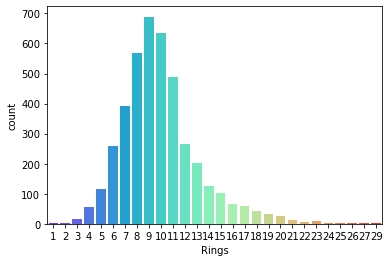

In [109]:
sns.countplot(df['Rings'], palette='rainbow')

In [110]:
print(df['Rings'].value_counts())

9     689
10    634
8     568
11    487
7     391
12    267
6     259
13    203
14    126
5     115
15    103
16     67
17     58
4      57
18     42
19     32
20     26
3      15
21     14
23      9
22      6
24      2
27      2
1       1
25      1
2       1
26      1
29      1
Name: Rings, dtype: int64


##### Comment - 
1. Maximum number of  rings observe in abalone 9,10, 8 rings in decremental order.
2. No abalone has 28 rings.
3. The number of rings measured in the data ranges from 1 to 29 and most of the abalone have between 5 and 15 rings. 

### Distribution of features

In [101]:
features=df[df.columns[1:]]

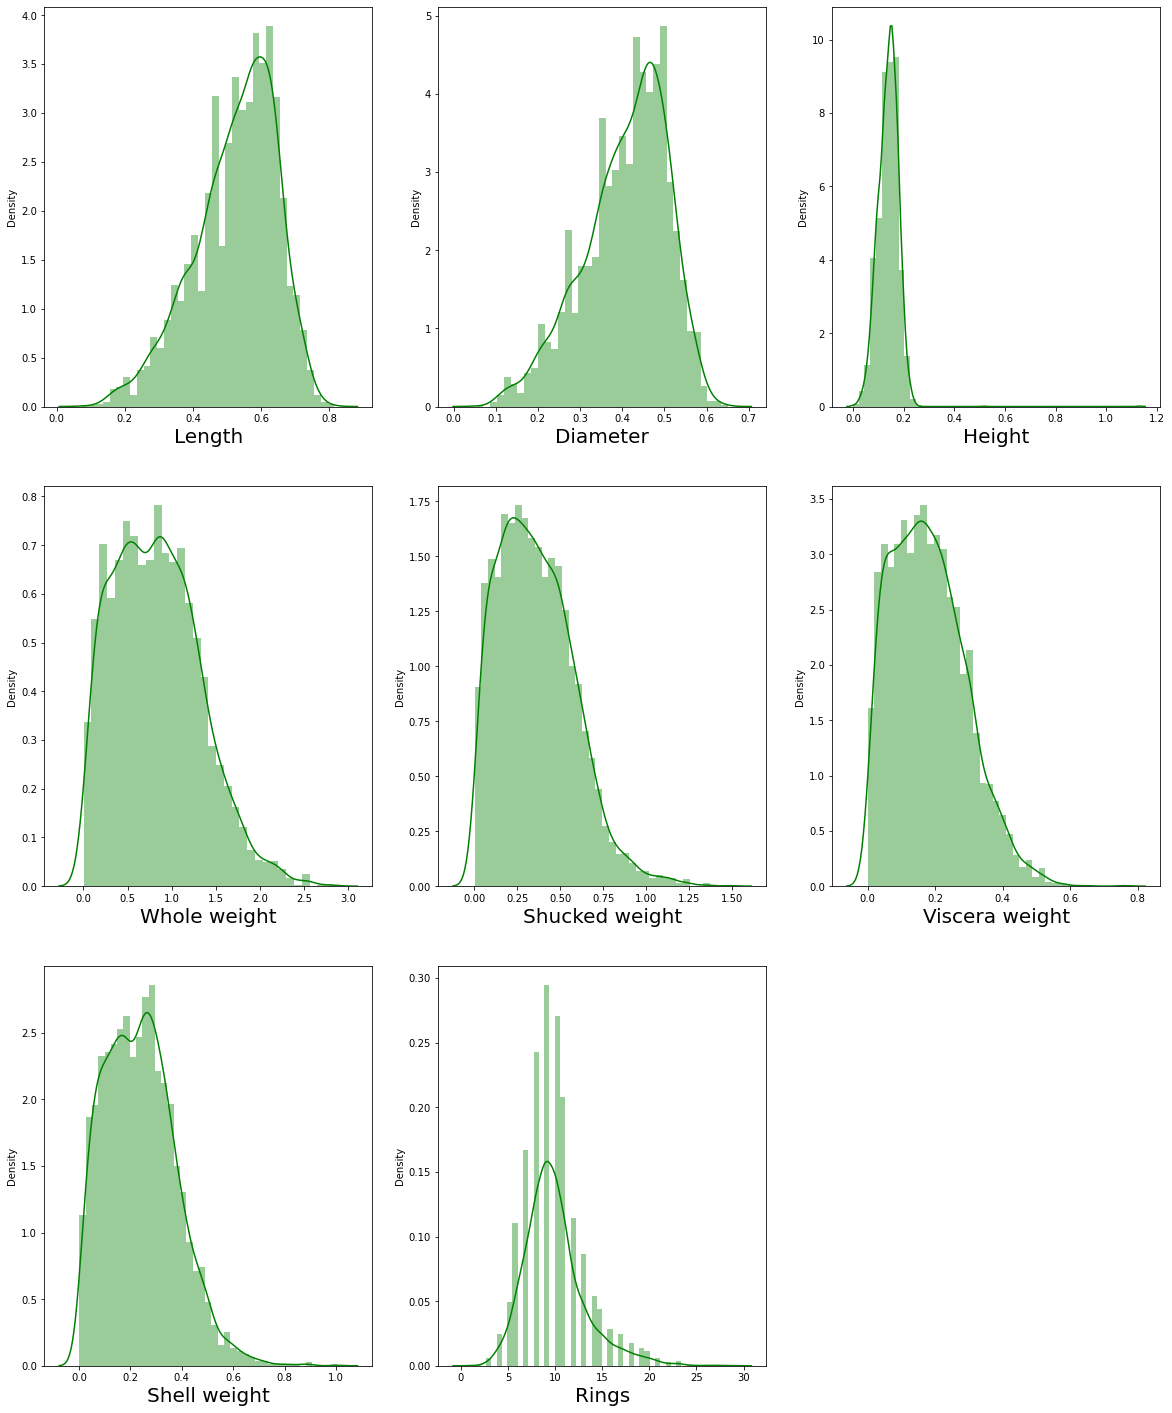

In [102]:
plt.figure(figsize=(20,25), facecolor='white')
plotnumber =1
for column in features:
    if plotnumber <=9:
        ax = plt.subplot(3,3,plotnumber)
        sns.distplot(features[column], color='g')
        plt.xlabel(column,fontsize=20)
    plotnumber+=1
plt.show()

### Interpreting Relationship between Dependent Variable and Independent Variables

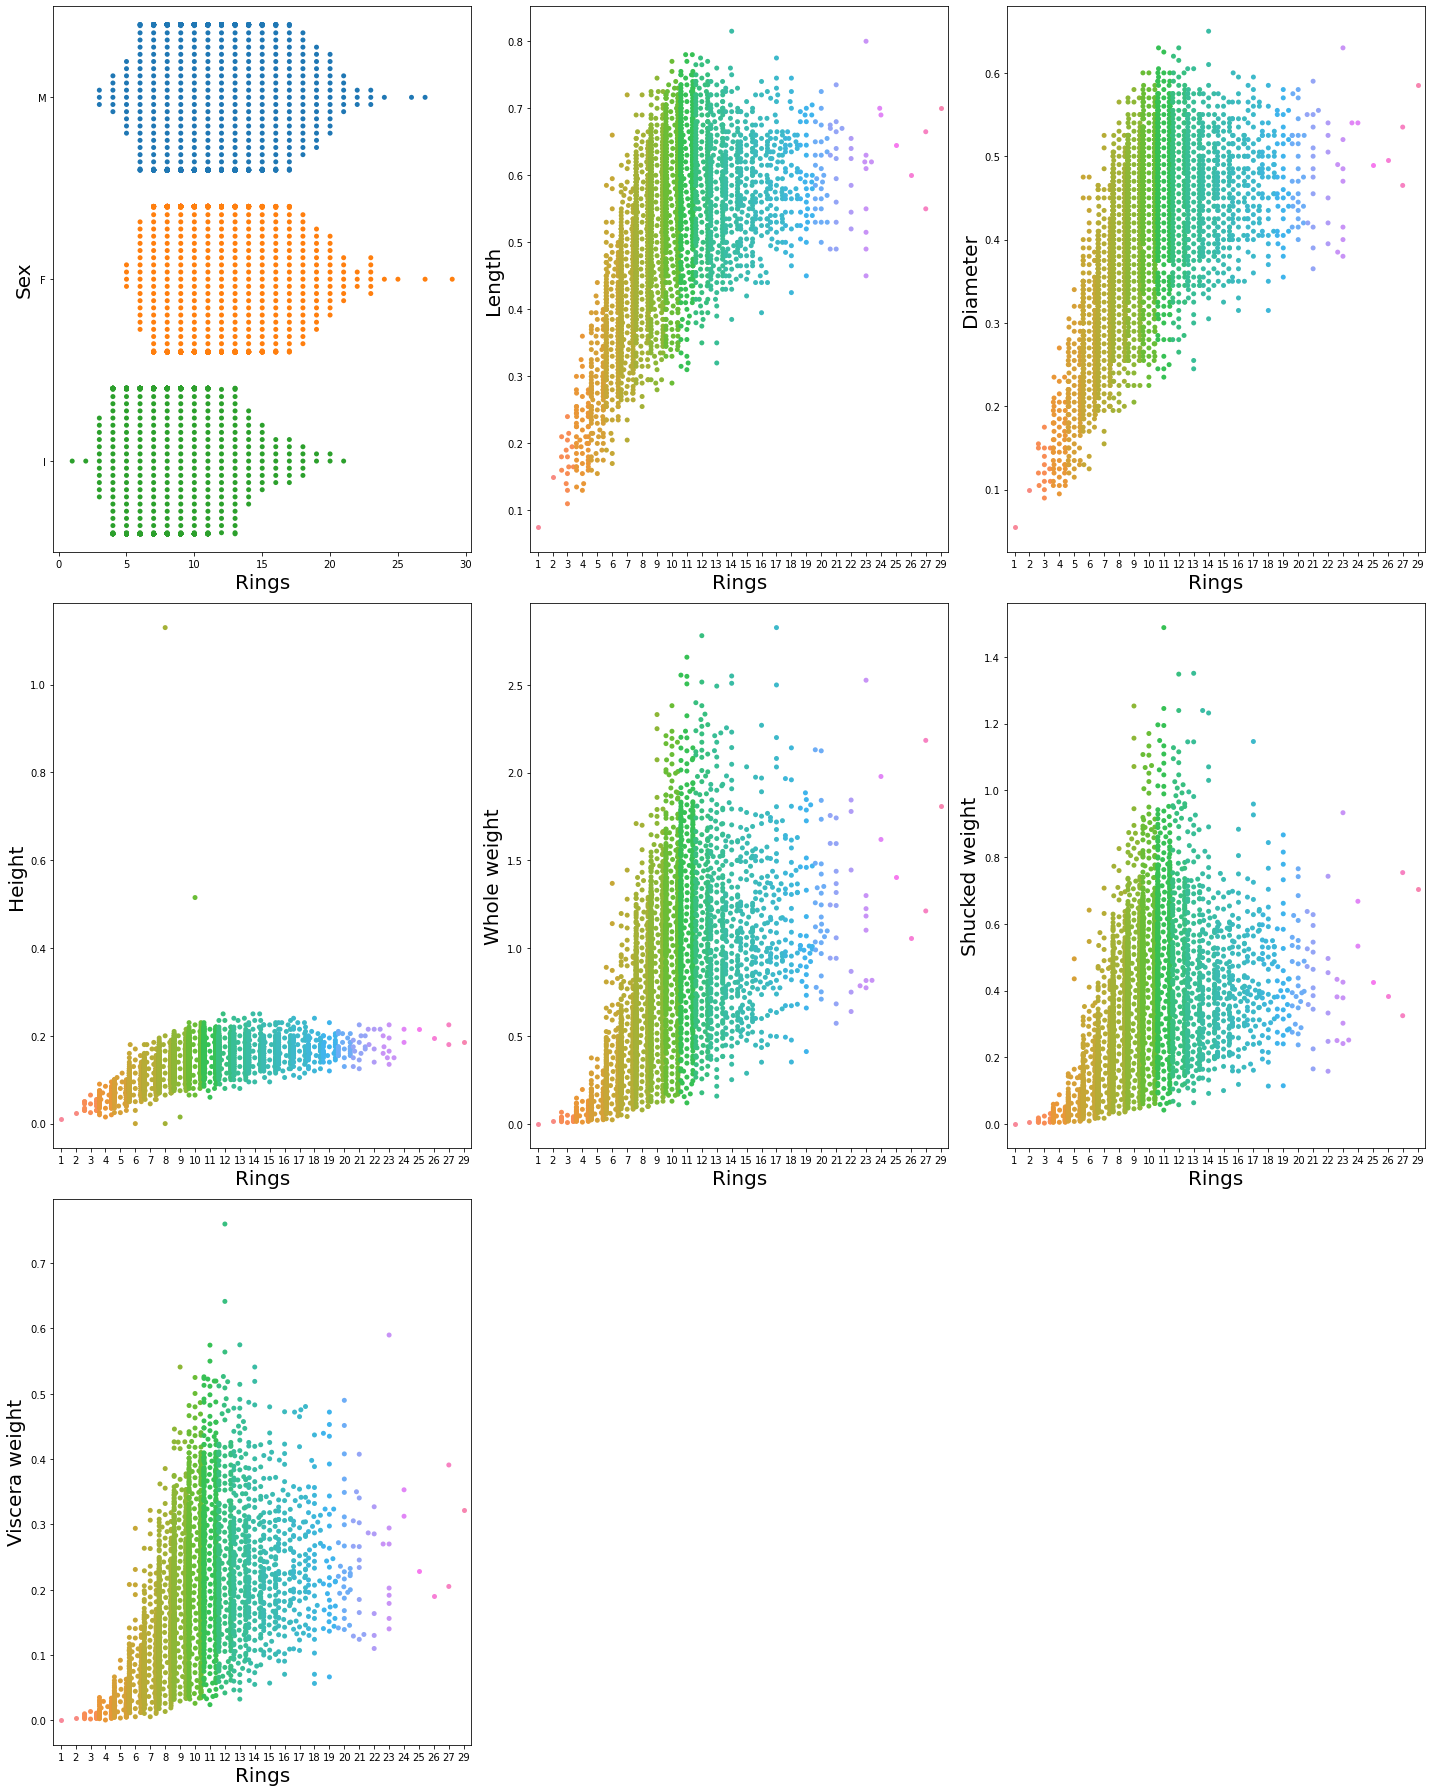

In [184]:
plt.figure(figsize=(20,25),facecolor='white')
plotnum=1
x = df['Rings']
for col in df:
    if plotnum<=7:
        plt.subplot(3,3,plotnum)
        sns.swarmplot(x,df[col])
        plt.xlabel('Rings',fontsize=20)
        plt.ylabel(col,fontsize=20)
    plotnum+=1
plt.tight_layout()

From the above graphs it is observed that infants have rings ranging from 0 to 21 while Male and female have rings ranging from 5 t0 29. This may imply a negative correlation between infants and number of rings. Length, Diameter and the different weight attributes show an almost linear relationship with the number of rings. The presence of outliers can also be seen in all the features.

## Multivariate Analysis

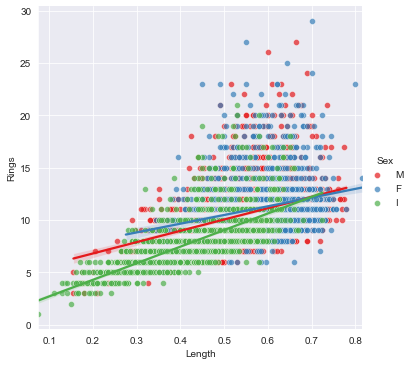

In [197]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Length', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

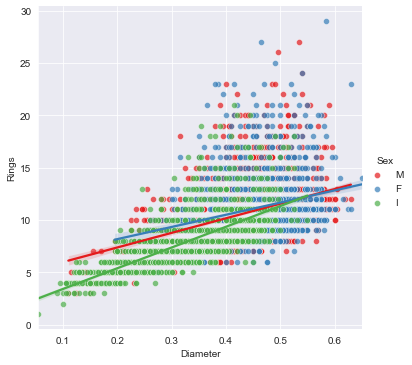

In [210]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Diameter', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

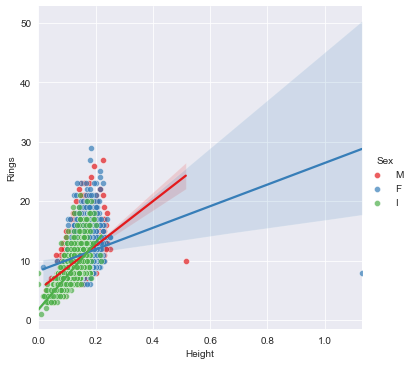

In [211]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Height', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

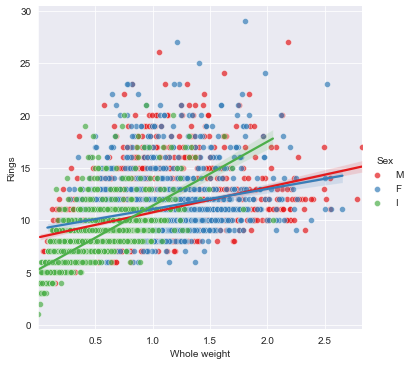

In [212]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Whole weight', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

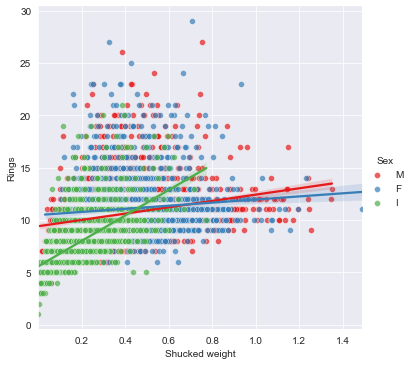

In [213]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Shucked weight', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

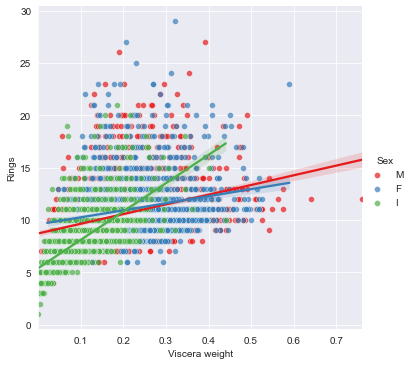

In [214]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Viscera weight', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

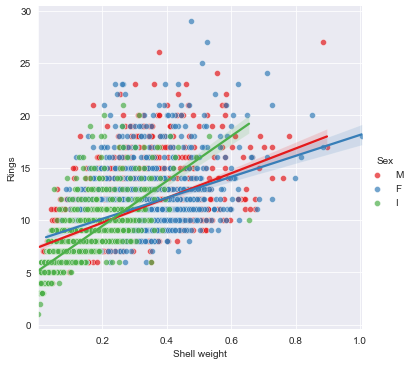

In [215]:
sns.set_style('darkgrid')
sns.lmplot(x = 'Shell weight', y = 'Rings', data = df, hue = 'Sex', palette = 'Set1', 
           scatter_kws={'edgecolor':'white', 'alpha':0.7, 'linewidth':0.5})

### Multivariate Anaysis using Joint grid

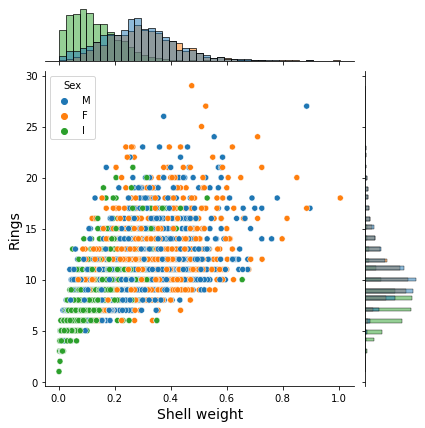

In [104]:
g = sns.JointGrid(data=df, x='Shell weight', y='Rings', hue='Sex')
g.plot(sns.scatterplot, sns.histplot)
g.set_axis_labels(xlabel='Shell weight', ylabel='Rings', fontsize=14)

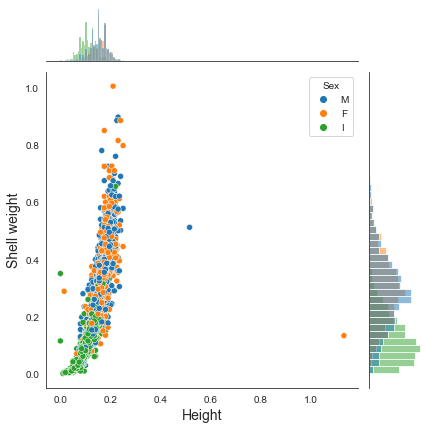

In [195]:
g = sns.JointGrid(data=df, x='Height', y='Shell weight', hue='Sex')
g.plot(sns.scatterplot, sns.histplot)
g.set_axis_labels(xlabel='Height', ylabel='Shell weight', fontsize=14)

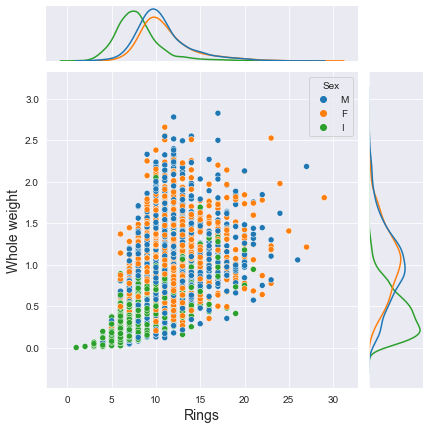

In [228]:
g = sns.JointGrid(data=df, x='Rings', y='Whole weight', hue='Sex')
g.plot(sns.scatterplot, sns.kdeplot)
g.set_axis_labels(xlabel='Rings', ylabel='Whole weight', fontsize=14)

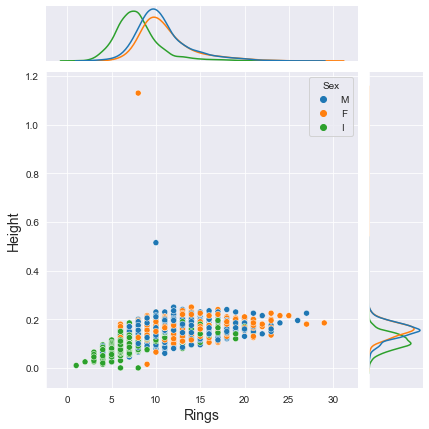

In [229]:
g = sns.JointGrid(data=df, x='Rings', y='Height', hue='Sex')
g.plot(sns.scatterplot, sns.kdeplot)
g.set_axis_labels(xlabel='Rings', ylabel='Height', fontsize=14)

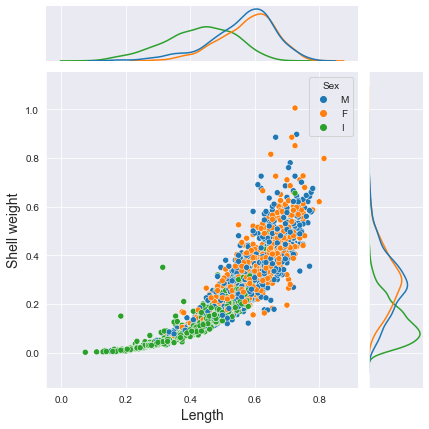

In [226]:
g = sns.JointGrid(data=df, x='Length', y='Shell weight', hue='Sex')
g.plot(sns.scatterplot, sns.kdeplot)
g.set_axis_labels(xlabel='Length', ylabel='Shell weight', fontsize=14)

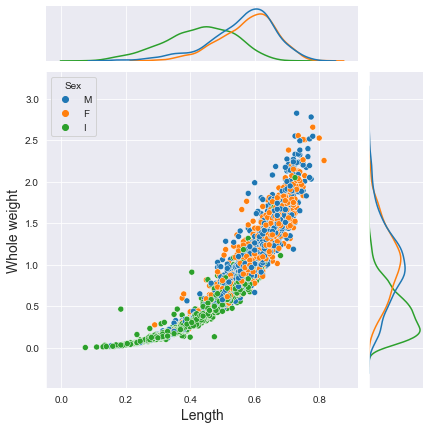

In [225]:
g = sns.JointGrid(data=df, x='Length', y='Whole weight', hue='Sex')
g.plot(sns.scatterplot, sns.kdeplot)
g.set_axis_labels(xlabel='Length', ylabel='Whole weight', fontsize=14)

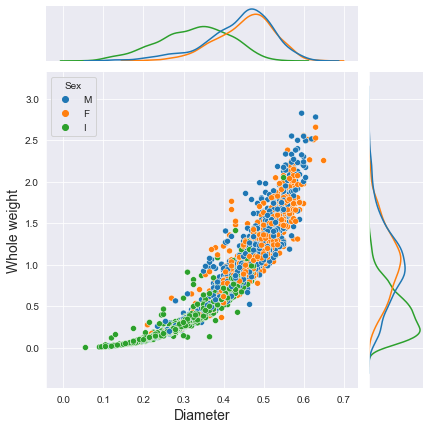

In [224]:
g = sns.JointGrid(data=df, x='Diameter', y='Whole weight', hue='Sex')
g.plot(sns.scatterplot, sns.kdeplot)
g.set_axis_labels(xlabel='Diameter', ylabel='Whole weight', fontsize=14)

## Correlation

In [105]:
df.corr()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
Length,1.000000,0.986812,0.827554,0.925261,0.897914,0.903018,0.897706,0.556720
Diameter,0.986812,1.000000,0.833684,0.925452,0.893162,0.899724,0.905330,0.574660
Height,0.827554,0.833684,1.000000,0.819221,0.774972,0.798319,0.817338,0.557467
Whole weight,0.925261,0.925452,0.819221,1.000000,0.969405,0.966375,0.955355,0.540390
Shucked weight,0.897914,0.893162,0.774972,0.969405,1.000000,0.931961,0.882617,0.420884
Viscera weight,0.903018,0.899724,0.798319,0.966375,0.931961,1.000000,0.907656,0.503819
Shell weight,0.897706,0.905330,0.817338,0.955355,0.882617,0.907656,1.000000,0.627574
Rings,0.556720,0.574660,0.557467,0.540390,0.420884,0.503819,0.627574,1.000000


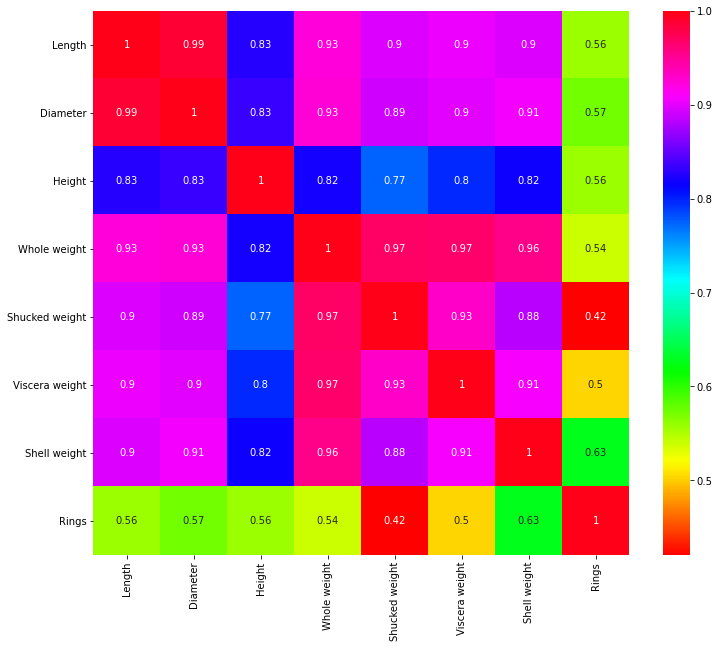

In [106]:
plt.figure(figsize =(12,10))
sns.heatmap(df.corr(), annot= True ,cmap='hsv')
# cmap =PiYG cmap='Spectral'
plt.tight_layout
plt.show()

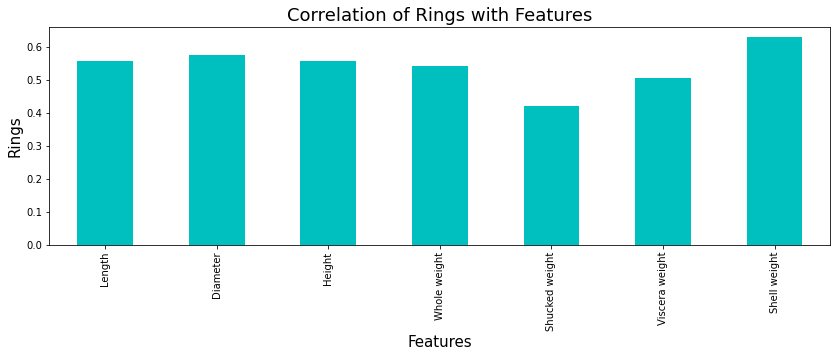

In [107]:
plt.figure(figsize = (14,4))
df.corr()['Rings'].drop(['Rings']).plot(kind='bar',color = 'c')
plt.xlabel('Features',fontsize=15)
plt.ylabel('Rings',fontsize=15)
plt.title('Correlation of Rings with Features',fontsize = 18)
plt.show()

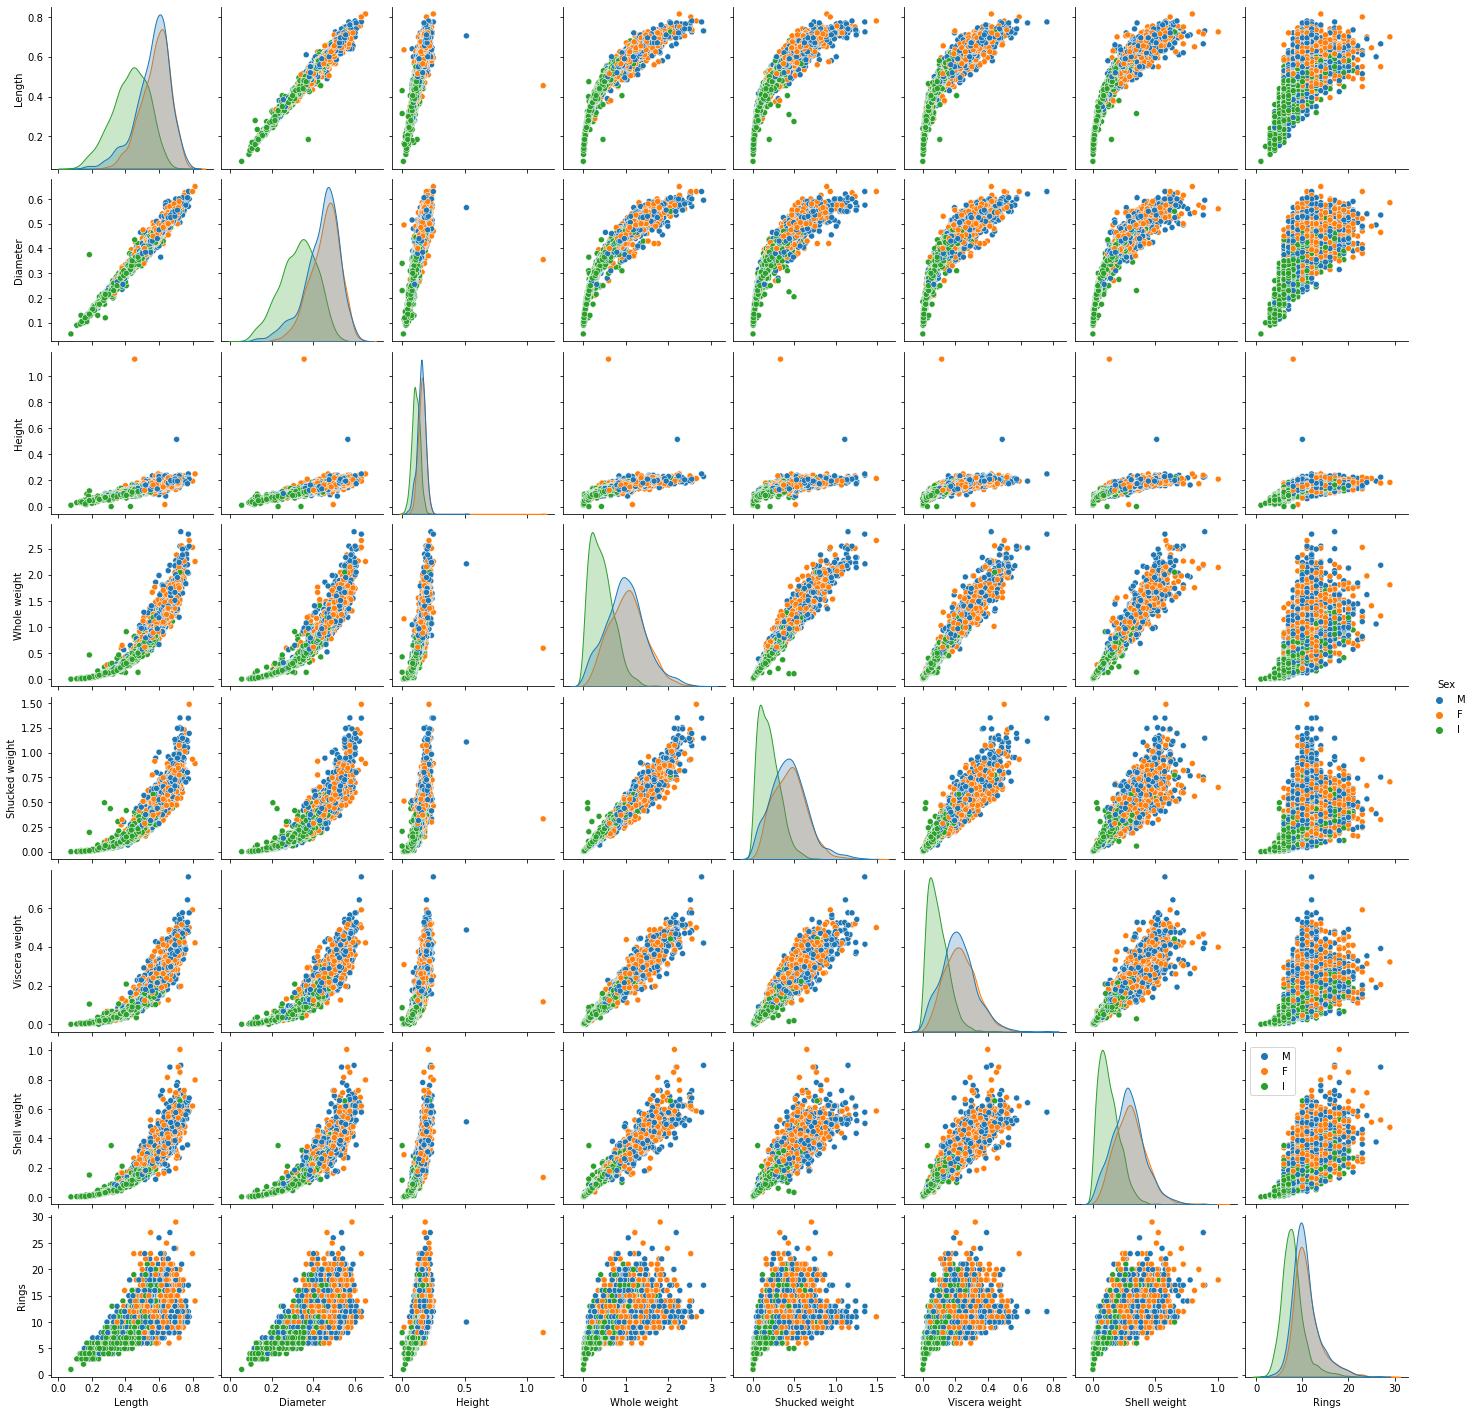

In [108]:
sns.pairplot(data=df, hue='Sex')
plt.legend()
plt.show()

#### Comment -
    
    1. Many features are highly correlated
        - length and diameter show linear correlation
        - the length and weight features are quadratic correlated
        - whole weight is linearly correlated with other weight features
    2. Number of Rings is positively corelated with almost all quadratic features
    3. Possible outliers in Height features
    
Scatter plot analysis also shows that data mostly cover the values for Rings from 3 to little over 20, selecting only this data in the model may be taken under consideration to increase the accuracy.

---------------------------------------------------------------------------------------------------------------------------

# Outliers Detection and Removal

#### From df.describe in height column we can see 0 value in height column. It can be valid data point or possibly Outliers.  We will investigate these observations

In [111]:
(df.Height ==0).sum()

2

In [112]:
df[df['Height'] ==0 ]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


#### Comment - 
1. We can see that both are infants having 8 and 6 rings respectively. 
2. There are two obeservations for which Height might not be recoreded properly as other features seem to have valid values. 
3. We can also see that whole weight values are very low and fall within 1st quartile. 

This might not be error so we will keep these entries for futher investigation.

<AxesSubplot:ylabel='Rings'>

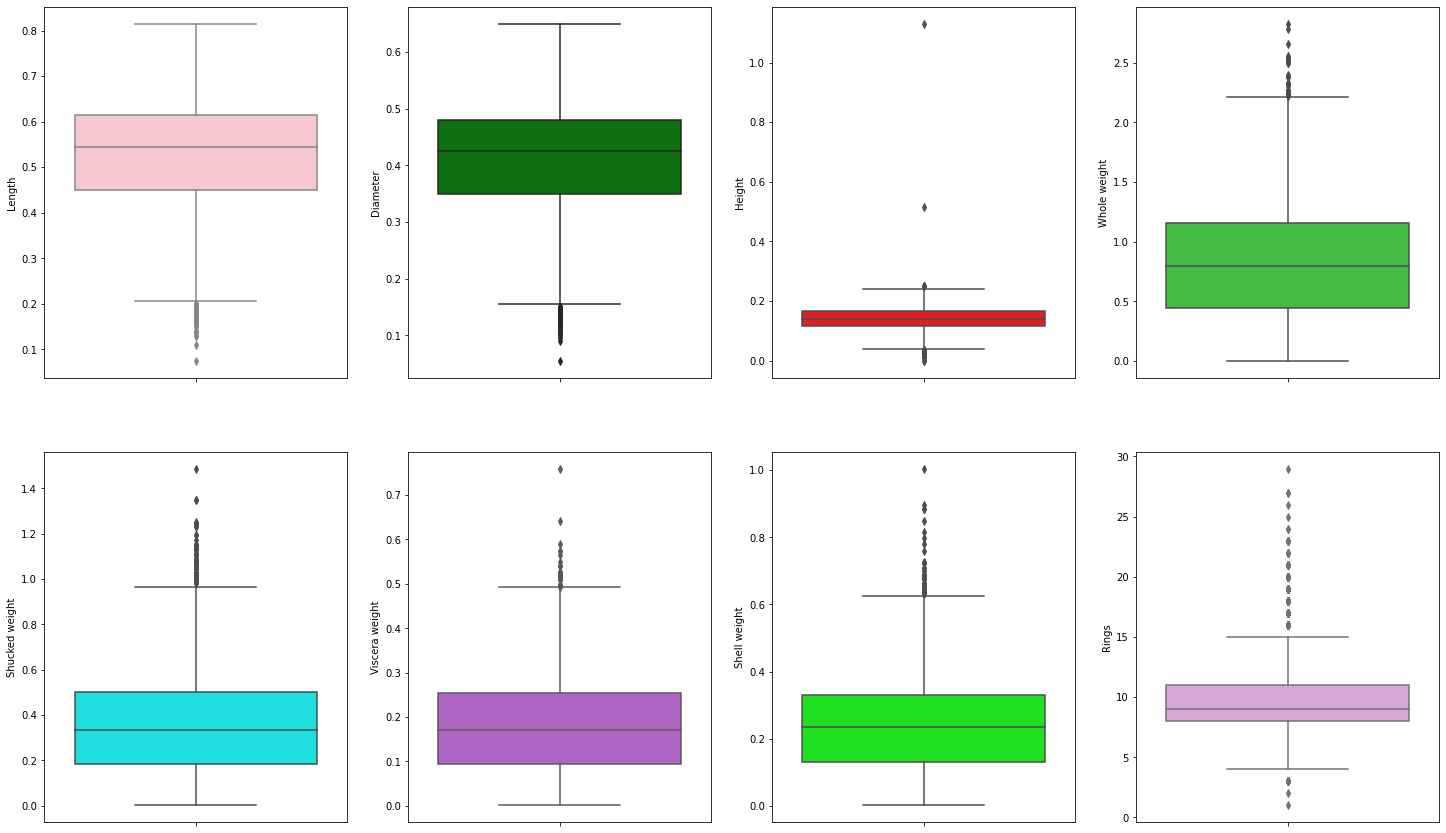

In [113]:
fig, ((ax1,ax2,ax3,ax4), (ax5,ax6,ax7,ax8)) =plt.subplots(nrows =2,ncols=4, figsize =(25,15))
sns.boxplot(ax =ax1, y='Length', data=df, color ='Pink')
sns.boxplot(ax=ax2, y='Diameter', data=df, color= 'green')
sns.boxplot(ax=ax3, y='Height', data=df, color= 'red')
sns.boxplot(ax=ax4, y='Whole weight', data=df, color= 'limegreen')
sns.boxplot(ax=ax5, y='Shucked weight', data=df, color= 'cyan')
sns.boxplot(ax=ax6, y='Viscera weight', data=df, color= 'mediumorchid')
sns.boxplot(ax=ax7, y='Shell weight', data=df, color= 'lime')
sns.boxplot(ax=ax8, y='Rings', data=df, color= 'plum')

## Outliers Detection basesd on IQR 

In [114]:
df2 =df.copy()
Q1 =df2.quantile(0.25)
Q3= df2.quantile(0.75)
IQR = Q3-Q1
print(IQR)

Length            0.1650
Diameter          0.1300
Height            0.0500
Whole weight      0.7115
Shucked weight    0.3160
Viscera weight    0.1595
Shell weight      0.1990
Rings             3.0000
dtype: float64


In [115]:
df_new =df2[~((df <(Q1 - 1.5*IQR)) | (df >(Q3 + 1.5*IQR))).any(axis=1)]
print(df_new.shape)

(3781, 9)


##### Data Loss

In [116]:
print("\033[1m"+'Percentage Data Loss :'+"\033[0m",((4177-3781)/4177)*100,'%')

Percentage Data Loss : 9.480488388795786 %


#### Comment -
1. There is significant data loss using IQR method.
2. From pairplot and Boxplot we know that outliers are present in dataset but as datapoints are not much scatter.
3. Most of outliers exist in 4th quartile of dataset as we can see in boxplot.
##### Different outlier detection criteria require in this case.

## Quantile-based Flooring and Capping technique

### Further outliers investigation will be done bases Quantile-based Flooring and Capping technique. In this technique, we will do the flooring (e.g., the 10th percentile) for the lower values and capping (e.g., the 75th percentile) for the higher values.

In [117]:
df3=df.copy()
Q1 = df3.quantile(0.10)
Q3= df3.quantile(0.75)
IQR = Q3 - Q1
print(IQR)

Length            0.2600
Diameter          0.2150
Height            0.0750
Whole weight      0.9480
Shucked weight    0.4155
Viscera weight    0.2097
Shell weight      0.2640
Rings             5.0000
dtype: float64


In [118]:
data = df3[~((df3 < (Q1 - 1.5 * IQR)) |(df3 > (Q3 + 1.5 * IQR))).any(axis=1)]
print(data.shape)

(4052, 9)


##### Data Loss

In [119]:
print("\033[1m"+'Percentage Data Loss :'+"\033[0m",((4177-4052)/4177)*100,'%')

Percentage Data Loss : 2.9925784055542257 %


--------------------------------------------------------------------------------------------------------------------------

## Label Encoding

In [120]:
data['Sex']=data['Sex'].astype('category')

In [121]:
from sklearn.preprocessing import LabelEncoder
labelencoder=LabelEncoder()
data['Sex']=labelencoder.fit_transform(data['Sex'])

In [122]:
data.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,2,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,2,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,0,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,2,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,1,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


---------------------------------------------------------------------------------------------------------------------------

## Multicollinearity and Skewness Handling

### Skewness of features using distplot

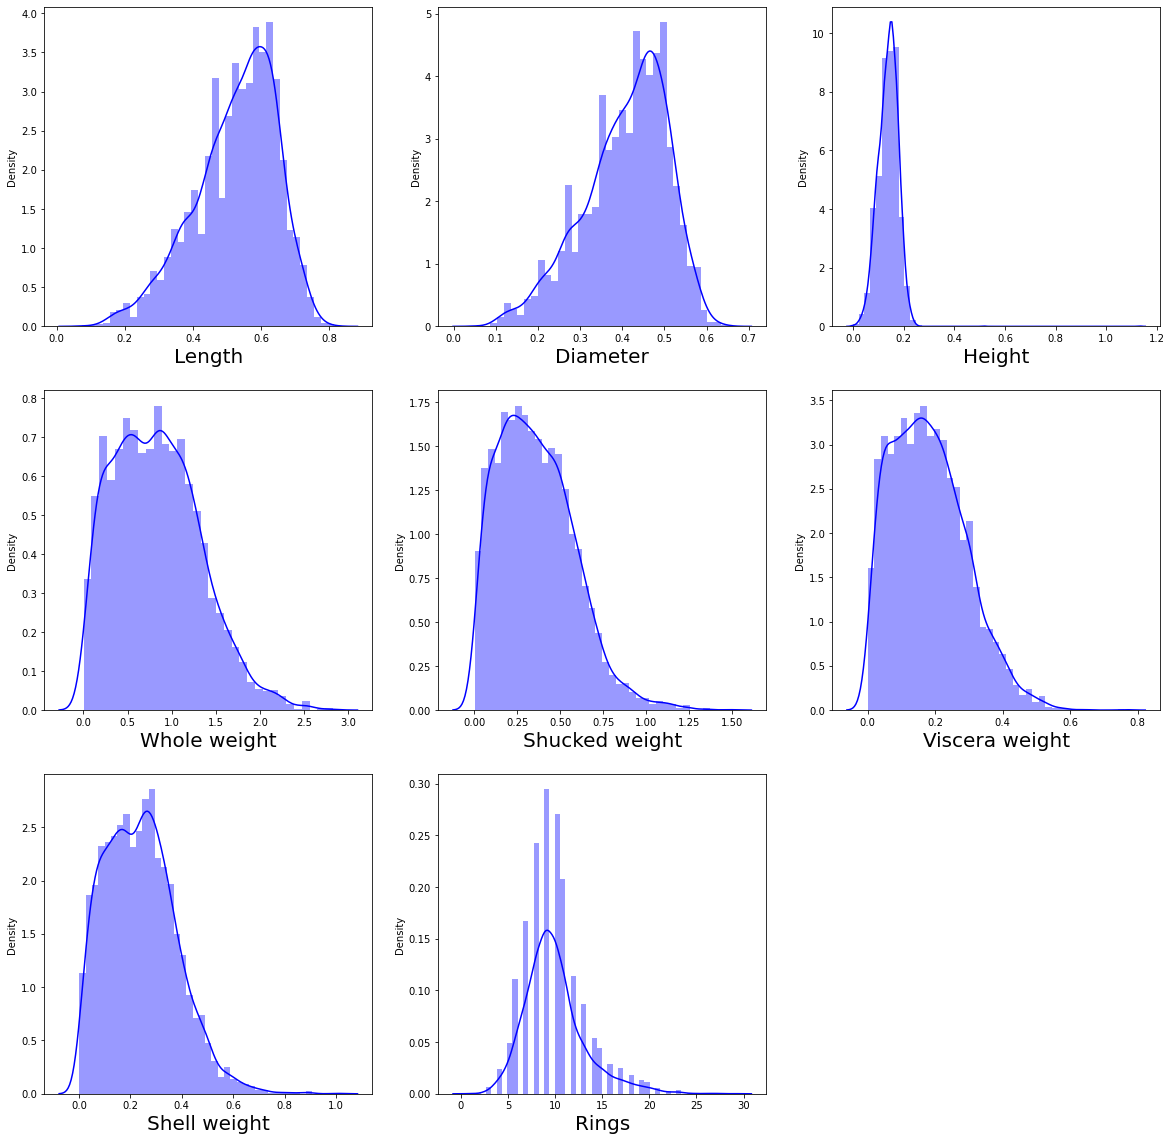

In [175]:
plt.figure(figsize=(20,20), facecolor='white')
plotnumber =1
for column in features:
    if plotnumber <=9:
        ax = plt.subplot(3,3,plotnumber)
        sns.distplot(features[column], color='b')
        plt.xlabel(column,fontsize=20)
    plotnumber+=1
plt.show()

In [124]:
data.skew()

Sex              -0.098740
Length           -0.650687
Diameter         -0.625802
Height           -0.286475
Whole weight      0.423612
Shucked weight    0.549819
Viscera weight    0.515935
Shell weight      0.435418
Rings             0.556027
dtype: float64

#### Comment -
1. Optimal range for skewness is -0.5 to 0.5.
2. Shucked weight, Viscera weight, Rings are positive/right skewed data.
3. Length, Diameter are Negtive/left skewed data.

#### Transforming positive or right skew data using boxcox transformation

In [125]:
from scipy.stats import boxcox

In [126]:
data['Rings']=boxcox(data['Rings'],0.5)

In [127]:
data['Viscera weight']=boxcox(data['Viscera weight'],0.5)

In [128]:
data['Shucked weight']=boxcox(data['Shucked weight'],0.5)

#### Transforming negative or left skew data using yeo-johnson transformation

In [129]:
from sklearn.preprocessing import PowerTransformer
from sklearn.compose import ColumnTransformer

In [130]:
ld=['Length','Diameter']
ds =data[ld].copy()

In [131]:
column_trans =ColumnTransformer(
    [('Length',PowerTransformer(method='yeo-johnson',standardize=True),['Length']),
    ('Diameter',PowerTransformer(method='yeo-johnson',standardize=True),['Diameter'])])
transformed_yeojohnson =column_trans.fit_transform(data)   
new_cols=['Length','Diameter']
dataset=pd.DataFrame(transformed_yeojohnson,columns=new_cols) #to convert numpy array back into dataframe
pd.concat([dataset],axis=1)
dataset.head()

,Length,Diameter
0,-0.667193,-0.531736
1,-1.381113,-1.372683
2,-0.044838,0.035534
3,-0.779907,-0.531736
4,-1.498357,-1.444649


In [132]:
# reseting index and mergeing transform data
data.reset_index(drop=True, inplace=True)
dataset.index=data.index
data[ld]=dataset[ld]
data

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,2,-0.667193,-0.531736,0.095,0.5140,-1.052371,-1.364390,0.1500,5.745967
1,2,-1.381113,-1.372683,0.090,0.2255,-1.369128,-1.559546,0.0700,3.291503
2,0,-0.044838,0.035534,0.135,0.6770,-0.987083,-1.247670,0.2100,4.000000
3,2,-0.779907,-0.531736,0.125,0.5160,-1.071560,-1.324722,0.1550,4.324555
4,1,-1.498357,-1.444649,0.080,0.2050,-1.401669,-1.602508,0.0550,3.291503
...,...,...,...,...,...,...,...,...,...
4047,0,0.281266,0.380105,0.165,0.8870,-0.783447,-1.022247,0.2490,4.633250
4048,2,0.529023,0.262363,0.135,0.9660,-0.674858,-1.073717,0.2605,4.324555
4049,2,0.631701,0.687500,0.205,1.1760,-0.550172,-0.927619,0.3080,4.000000
4050,0,0.897584,0.815816,0.150,1.0945,-0.542605,-0.978237,0.2960,4.324555


#### Skewness after transforming features

In [133]:
data.skew()

Sex              -0.098740
Length           -0.075717
Diameter         -0.077474
Height           -0.286475
Whole weight      0.423612
Shucked weight   -0.204152
Viscera weight   -0.210265
Shell weight      0.435418
Rings             0.069836
dtype: float64

#### Heamap of correlation after removing skewness

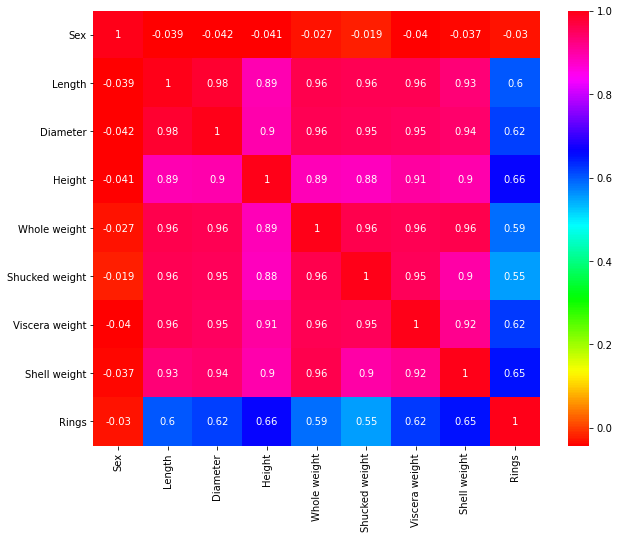

In [134]:
plt.figure(figsize =(10,8))
sns.heatmap(data.corr(), annot= True ,cmap='hsv')
plt.tight_layout
plt.show()

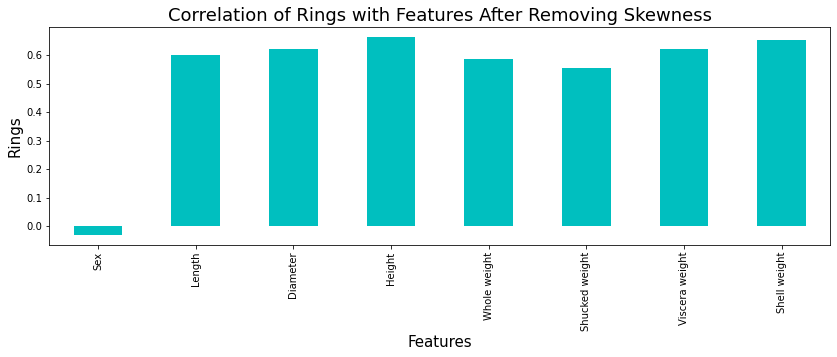

In [135]:
plt.figure(figsize = (14,4))
data.corr()['Rings'].drop(['Rings']).plot(kind='bar',color = 'c')
plt.xlabel('Features',fontsize=15)
plt.ylabel('Rings',fontsize=15)
plt.title('Correlation of Rings with Features After Removing Skewness',fontsize = 18)
plt.show()

### Checking Multicollinearity between features using variance_inflation_factor

In [136]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
data2=data.copy()
vif= pd.DataFrame()
vif['VIF']= [variance_inflation_factor(data2.values,i) for i in range(data2.shape[1])]
vif['Features']= data2.columns
vif

,VIF,Features
0,2.685293,Sex
1,35.352904,Length
2,34.852697,Diameter
3,75.984114,Height
4,88.752092,Whole weight
5,118.556804,Shucked weight
6,148.416528,Viscera weight
7,72.406172,Shell weight
8,44.006491,Rings


#### Comment -
1. We looked that variable inflation factor for all variable and it appears that all predictors have multicollinearity issue
2. Length, diameter and height are geometrical physical dimension of abalone.These all parameter are highly correleated.
3. Variable Whole_weight should be the linear function of variables Shucked_weight, Viscersa_weight and Shell_weight, and we could write it as Whole_weight = Shucked_weight + Viscera_weight+ Shell_weight + unknown mass of water/blood lost from shucking process. So we can find high colliearity between these features.
4. for further investigation we will drop height and viscera Weight.

#### Checking Multicollinearity after removal of features

In [137]:
X=data2.drop(columns=['Height','Viscera weight'])

In [138]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif= pd.DataFrame()
vif['VIF']= [variance_inflation_factor(X.values,i) for i in range(X.shape[1])]
vif['Features']= X.columns
vif

,VIF,Features
0,2.652107,Sex
1,35.179385,Length
2,34.640586,Diameter
3,59.699239,Whole weight
4,38.303510,Shucked weight
5,67.622228,Shell weight
6,36.609555,Rings


##### Still there is multicollinearity. So we will deal with by apply standard scalar and Pca

--------------------------------------------------------------------------------------------------------------------------

## Standard Scaling

In [139]:
X=data.drop(columns =['Rings'])
Y=data['Rings']

In [58]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_scale = scaler.fit_transform(X)

In [59]:
X_scale

array([[ 1.15871651, -0.66719347, -0.53173608, ..., -0.45191104,
        -0.58987501, -0.62038691],
       [ 1.15871651, -1.38111305, -1.37268345, ..., -1.27245908,
        -1.30730107, -1.2267264 ],
       [-1.28984636, -0.04483754,  0.03553368, ..., -0.28278441,
        -0.16079282, -0.16563229],
       ...,
       [ 1.15871651,  0.63170098,  0.68750046, ...,  0.84902122,
         1.01576966,  0.57713359],
       [-1.28984636,  0.89758383,  0.81581625, ...,  0.86862425,
         0.82969148,  0.48618267],
       [ 1.15871651,  1.90531107,  1.80516153, ...,  2.13106882,
         1.58488325,  1.99445216]])

---------------------------------------------------------------------------------------------------------------------------

## PCA 

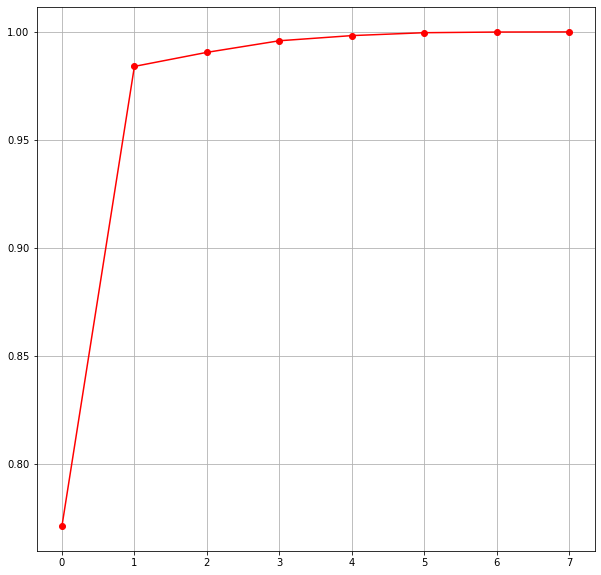

In [140]:
from sklearn.decomposition import PCA
pca = PCA()
#plot the graph to find the principal components
x_pca = pca.fit_transform(X)
plt.figure(figsize=(10,10))
plt.plot(np.cumsum(pca.explained_variance_ratio_), 'ro-')
plt.grid()

#### Comment -
###### AS per the graph, we can see that 4 principal components attribute for 90% of variation in the data.  We shall pick the first 4 components for our prediction

In [141]:
pca_new = PCA(n_components=4)
x_new = pca_new.fit_transform(X)
print(x_new)

[[-0.95708523 -0.9200266  -0.04708159  0.07850657]
 [-2.15275948 -0.88703141  0.03288157  0.03072876]
 [-0.05067072  1.05720501 -0.15376956 -0.02746878]
 ...
 [ 1.05916586 -0.97728443  0.06849842  0.08175901]
 [ 1.33445377  1.01689141 -0.02205043 -0.09623901]
 [ 2.97720758 -1.0331803   0.23711656  0.07564047]]


---------------------------------------------------------------------------------------------------------------------------

# Machine Learning Model Building

In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import  GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import  Ridge
from sklearn.linear_model import  Lasso

In [142]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=42, test_size=.33)
print('Training feature matrix size:',X_train.shape)
print('Training target vector size:',Y_train.shape)
print('Test feature matrix size:',X_test.shape)
print('Test target vector size:',Y_test.shape)

Training feature matrix size: (2714, 8)
Training target vector size: (2714,)
Test feature matrix size: (1338, 8)
Test target vector size: (1338,)


####  Finding Best Random state

In [143]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
maxR2_score=0
maxRS=0
for i in range(1,200):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=i, test_size=.33)
    lin_reg=LinearRegression()
    lin_reg.fit(X_train,Y_train)
    y_pred=lin_reg.predict(X_test)
    R2=r2_score(Y_test,y_pred)
    if R2>maxR2_score:
        maxR2_score=R2
        maxRS=i
print('Best R2 Score is', maxR2_score ,'on Random_state', maxRS)

Best R2 Score is 0.5630439924181885 on Random_state 98


## Linear Regression : Base model

In [144]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=98, test_size=.3)
lin_reg=LinearRegression()
lin_reg.fit(X_train,Y_train)
lin_reg.score(X_train,Y_train)
y_pred=lin_reg.predict(X_test)
print('\033[1m'+'Predicted Number Rings:'+'\033[0m\n',y_pred)
print('\n')
print('\033[1m'+'Actual Number of Rings:'+'\033[0m\n',Y_test)

Predicted Number Rings:
 [3.3346865  4.9639436  4.49489252 ... 4.63569838 4.3318562  5.03008816]


Actual Number of Rings:
 2389    3.656854
1303    4.324555
2933    4.633250
2957    4.633250
3710    4.928203
          ...   
3760    3.291503
3046    4.633250
3568    4.324555
3498    4.000000
2082    5.483315
Name: Rings, Length: 1216, dtype: float64


### Linear Regression Evaluation Matrix

In [145]:
print('\033[1m'+' Error :'+'\033[0m')
print('Mean absolute error :', mean_absolute_error(Y_test,y_pred))
print('Mean squared error :', mean_squared_error(Y_test,y_pred))
print('Root Mean Squared Error:', np.sqrt(mean_squared_error(Y_test,y_pred)))
print('\n')
from sklearn.metrics import r2_score
print('\033[1m'+' R2 Score :'+'\033[0m')
print(r2_score(Y_test,y_pred))

 Error :
Mean absolute error : 0.46452169471062316
Mean squared error : 0.35906711419996584
Root Mean Squared Error: 0.5992220908811405


 R2 Score :
0.5619964599805789


 True Values Vs Predicted Value plot :


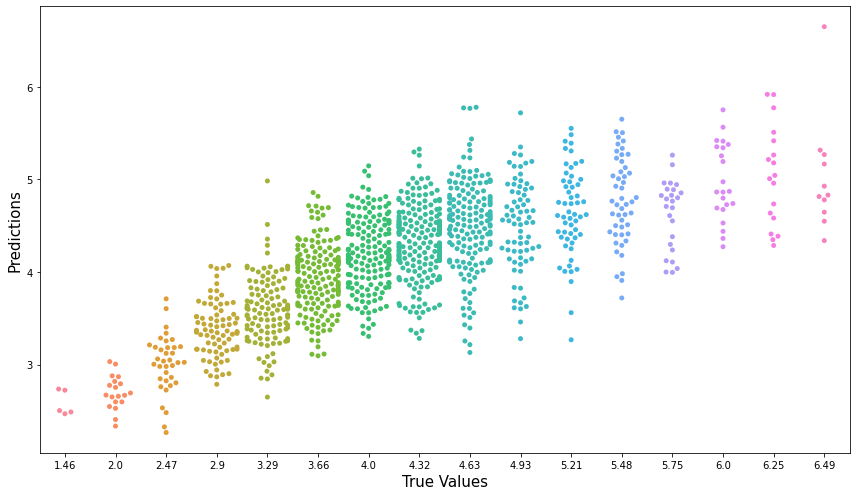

In [171]:
plt.figure(figsize=(12,7))
y_pred=lin_reg.predict(X_test)
sns.swarmplot(Y_test.round(2), y_pred)
print('\033[1m'+' True Values Vs Predicted Value plot :' +'\033[0m')
plt.xlabel('True Values' , fontsize=15)
plt.ylabel('Predictions', fontsize=15)
plt.tight_layout()

## Finding n_neighbors for KNN Regressor

In [146]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn import neighbors
from math import sqrt
from sklearn.metrics import mean_squared_error
rmse_val = [] #to store rmse values for different k
for K in range(40):
    K = K+1
    model = neighbors.KNeighborsRegressor(n_neighbors = K)

    model.fit(X_train,Y_train)  #fit the model
    y_pred=model.predict(X_test) #make prediction on test set
    error = sqrt(mean_squared_error(Y_test,y_pred)) #calculate rmse
    rmse_val.append(error) #store rmse values
    print('RMSE value for k= ' , K , 'is:', error)

RMSE value for k=  1 is: 0.7823930196337991
RMSE value for k=  2 is: 0.6870362515812698
RMSE value for k=  3 is: 0.6557271707130184
RMSE value for k=  4 is: 0.6429013691739962
RMSE value for k=  5 is: 0.6212277564557407
RMSE value for k=  6 is: 0.6120270898289828
RMSE value for k=  7 is: 0.6098657883913524
RMSE value for k=  8 is: 0.6073886279597739
RMSE value for k=  9 is: 0.6086379744267192
RMSE value for k=  10 is: 0.6104128292613764
RMSE value for k=  11 is: 0.6114123179345414
RMSE value for k=  12 is: 0.6069608086472568
RMSE value for k=  13 is: 0.6053305381324132
RMSE value for k=  14 is: 0.6046215381886418
RMSE value for k=  15 is: 0.6040115624368425
RMSE value for k=  16 is: 0.6060870177122096
RMSE value for k=  17 is: 0.6054301881666659
RMSE value for k=  18 is: 0.6057899700491248
RMSE value for k=  19 is: 0.6065832602386136
RMSE value for k=  20 is: 0.605424212132155
RMSE value for k=  21 is: 0.6056734741168476
RMSE value for k=  22 is: 0.607408717003213
RMSE value for k=  23

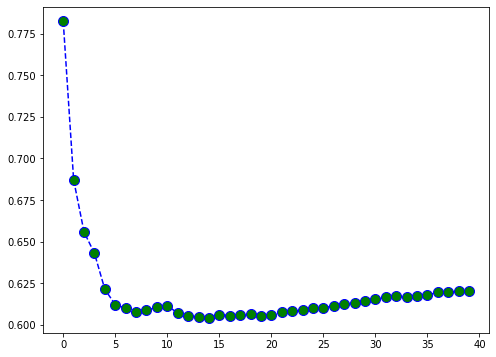

In [147]:
#plotting the rmse values against k values -
plt.figure(figsize = (8,6))
plt.plot(range(40), rmse_val, color='blue', linestyle='dashed', marker='o', markerfacecolor='green', markersize=10)

#### Comment- 
At k= 15, we get the minimum RMSE value which approximately 0.6040115624368425, and shoots up on further increasing the k value. We can safely say that k=20 will give us the best result in this case

---------------------------------------------------------------------------------------------------------------------------

## Applying other Regression Model

In [148]:
rf = RandomForestRegressor(n_estimators = 100 )
svr=SVR()
dtc = DecisionTreeRegressor()
adb=AdaBoostRegressor()
gradb=GradientBoostingRegressor()
knn=KNeighborsRegressor(n_neighbors=15)
model = [rf,svr,dtc,adb,gradb,knn]

for m in model:
    m.fit(X_train,Y_train)
    m.score(X_train,Y_train)
    y_pred = m.predict(X_test)
    print('\n')                                        
    print('\033[1m'+' Error of ', m, ':' +'\033[0m')
    print('Mean absolute error :', mean_absolute_error(Y_test,y_pred))
    print('Mean squared error :', mean_squared_error(Y_test,y_pred))
    print('Root Mean Squared Error:', np.sqrt(mean_squared_error(Y_test,y_pred)))
    print('\n')

    print('\033[1m'+' R2 Score :'+'\033[0m')
    print(r2_score(Y_test,y_pred)) 
    print('\n')
    print('==============================================================================================================')



 Error of  RandomForestRegressor() :
Mean absolute error : 0.42751735857552015
Mean squared error : 0.3090565280334428
Root Mean Squared Error: 0.5559285278104037


 R2 Score :
0.6230012496511377




 Error of  SVR() :
Mean absolute error : 0.42759090773801584
Mean squared error : 0.3167356464359087
Root Mean Squared Error: 0.5627927206671286


 R2 Score :
0.6136339728622218




 Error of  DecisionTreeRegressor() :
Mean absolute error : 0.5694620451949123
Mean squared error : 0.5974099341717979
Root Mean Squared Error: 0.7729229807502154


 R2 Score :
0.2712569442817505




 Error of  AdaBoostRegressor() :
Mean absolute error : 0.50553781514062
Mean squared error : 0.39481255186066533
Root Mean Squared Error: 0.6283411110699867


 R2 Score :
0.5183928337620813




 Error of  GradientBoostingRegressor() :
Mean absolute error : 0.42013595470245796
Mean squared error : 0.2984306970899755
Root Mean Squared Error: 0.5462881081352362


 R2 Score :
0.6359630369739797




 Error of  KNeighbo

 True Values Vs Predicted Value plot RandomForestRegressor() :


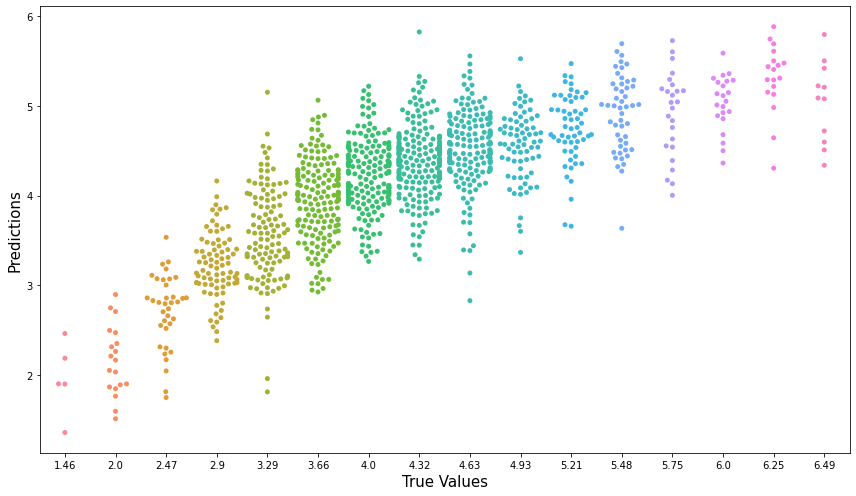



 True Values Vs Predicted Value plot SVR() :


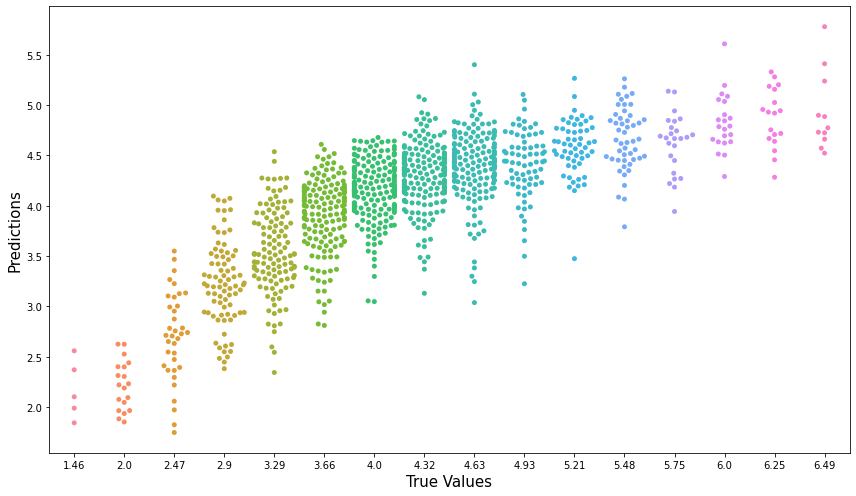



 True Values Vs Predicted Value plot DecisionTreeRegressor() :


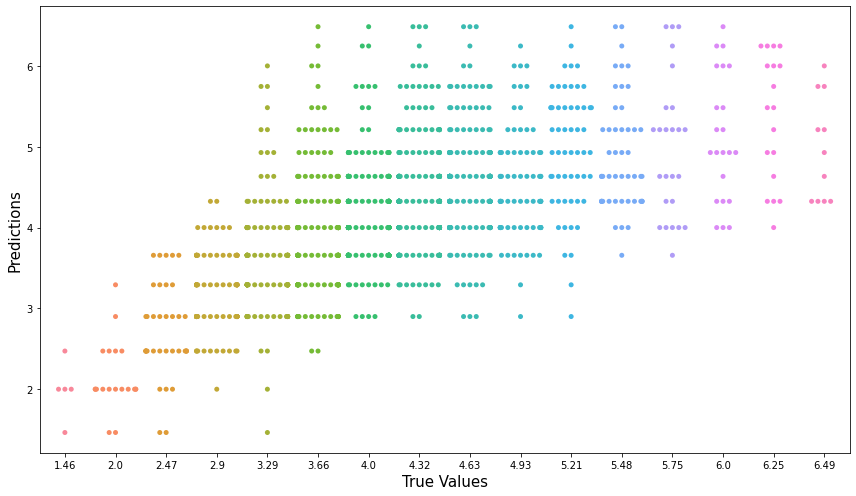



 True Values Vs Predicted Value plot AdaBoostRegressor() :


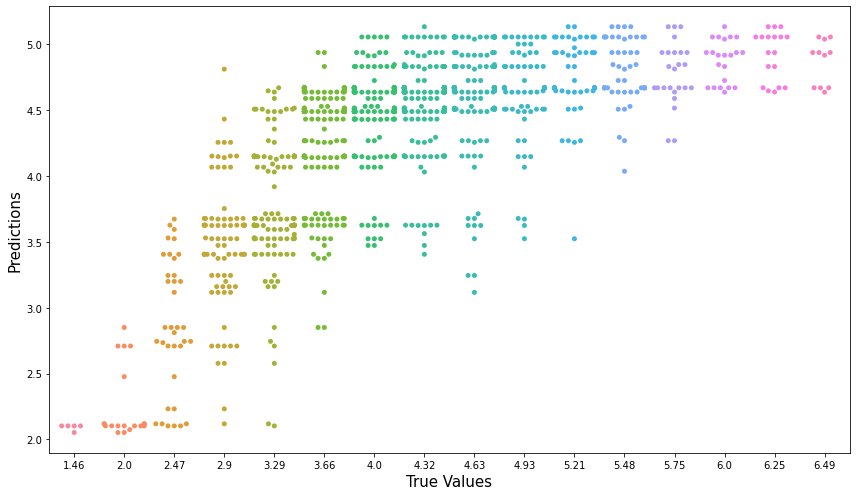



 True Values Vs Predicted Value plot GradientBoostingRegressor() :


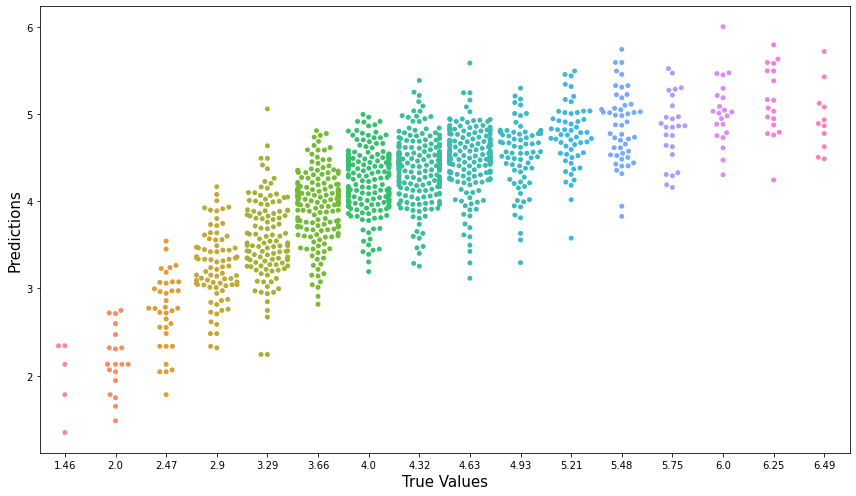



 True Values Vs Predicted Value plot KNeighborsRegressor(n_neighbors=15) :


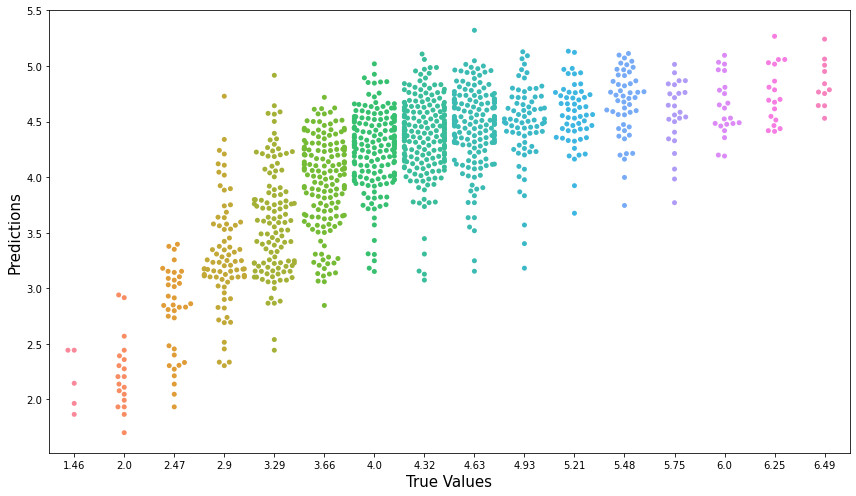

In [174]:
rf = RandomForestRegressor(n_estimators = 100 )
svr=SVR()
dtc = DecisionTreeRegressor()
adb=AdaBoostRegressor()
gradb=GradientBoostingRegressor()
knn=KNeighborsRegressor(n_neighbors=15)
model = [rf,svr,dtc,adb,gradb,knn]

for m in model:
    plt.figure(figsize=(12,7))
    m.fit(X_train,Y_train)
    y_pred=m.predict(X_test)
    print('\n')
    print('\033[1m'+' True Values Vs Predicted Value plot', m, ':' +'\033[0m')
    sns.swarmplot(Y_test.round(2), y_pred)
    plt.xlabel('True Values' , fontsize=15)
    plt.ylabel('Predictions', fontsize=15)
    plt.tight_layout()
    plt.show()
    print('\n')
    print('===================================================================================================')

---------------------------------------------------------------------------------------------------------------------------

# Cross Validation

In [150]:
from sklearn.model_selection import cross_val_score
model = [lin_reg,rf,svr,dtc,adb,gradb,knn]
for m in model:
    score = cross_val_score(m, X, Y, cv =4)
    print('\n')
    print('\033[1m'+'Cross Validation Score :',m,":"+'\033[0m\n')
    print("Score :" ,score)
    print("Mean Score :",score.mean())
    print("Std deviation :",score.std())
    print('\n')
    print('\033[1m'+' R2 Score :'+'\033[0m')
    print(r2_score(Y_test,y_pred))
    print('\n')
    print('==============================================================================================================')



Cross Validation Score : LinearRegression() :

Score : [0.49459189 0.29406677 0.54113423 0.48589347]
Mean Score : 0.4539215898723794
Std deviation : 0.09465183631178856


 R2 Score :
0.5549667152021102




Cross Validation Score : RandomForestRegressor() :

Score : [0.5895084  0.40198452 0.60798388 0.55892294]
Mean Score : 0.5395999360184072
Std deviation : 0.08136123420013261


 R2 Score :
0.5549667152021102




Cross Validation Score : SVR() :

Score : [0.53778773 0.54892582 0.59612773 0.56375654]
Mean Score : 0.5616494550215625
Std deviation : 0.021934358111009973


 R2 Score :
0.5549667152021102




Cross Validation Score : DecisionTreeRegressor() :

Score : [ 0.30334543 -0.32802613  0.3026801   0.14137073]
Mean Score : 0.1048425340718761
Std deviation : 0.258482440708945


 R2 Score :
0.5549667152021102




Cross Validation Score : AdaBoostRegressor() :

Score : [0.57156067 0.01917554 0.4553241  0.48199451]
Mean Score : 0.3820137066058622
Std deviation : 0.21386336769348374


 R

#### we can see that Gradient Boosting Regressor() gives maximum Accuracy. So we will apply Hyperparameter tuning on Gradient Boosting Regressor

# Hyper Parameter Tuning : GridSearchCV

In [152]:
from sklearn.model_selection import GridSearchCV

In [179]:
parameters = [{'learning_rate': [0.01,0.02,0.03],
                  'subsample'    : [0.9, 0.7,0.5, 0.3, 0.1],
                  'n_estimators' : [100,250,500,750],
                  'max_depth'    : [4,6,8,10,12]}] 

In [180]:
GCV = GridSearchCV(GradientBoostingRegressor(),parameters,cv=2,n_jobs = -1)
GCV.fit(X_train,Y_train)

GridSearchCV(cv=2, estimator=GradientBoostingRegressor(), n_jobs=-1,
             param_grid=[{'learning_rate': [0.01, 0.02, 0.03],
                          'max_depth': [4, 6, 8, 10, 12],
                          'n_estimators': [100, 250, 500, 750],
                          'subsample': [0.9, 0.7, 0.5, 0.3, 0.1]}])

In [183]:
GCV.best_params_

{'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 250, 'subsample': 0.3}

# Final Model

In [187]:
Final_mod = GradientBoostingRegressor(learning_rate=0.01 ,n_estimators= 250, max_depth=6 ,subsample=0.3)
Final_mod.fit(X_train,Y_train)
y_pred=Final_mod.predict(X_test)
print('\n')                                        
print('\033[1m'+' Error in Final Model :' +'\033[0m')
print('Mean absolute error :', mean_absolute_error(Y_test,y_pred))
print('Mean squared error :', mean_squared_error(Y_test,y_pred))
print('Root Mean Squared Error:', np.sqrt(mean_squared_error(Y_test,y_pred)))
print('\n')
print('\033[1m'+' R2 Score of Final Model :'+'\033[0m')
print(r2_score(Y_test,y_pred)) 
print('\n')



 Error in Final Model :
Mean absolute error : 0.42126658446485526
Mean squared error : 0.29945663417486823
Root Mean Squared Error: 0.5472263098343026


 R2 Score of Final Model :
0.6347115604191816




 True Values Vs Predicted Value plot :


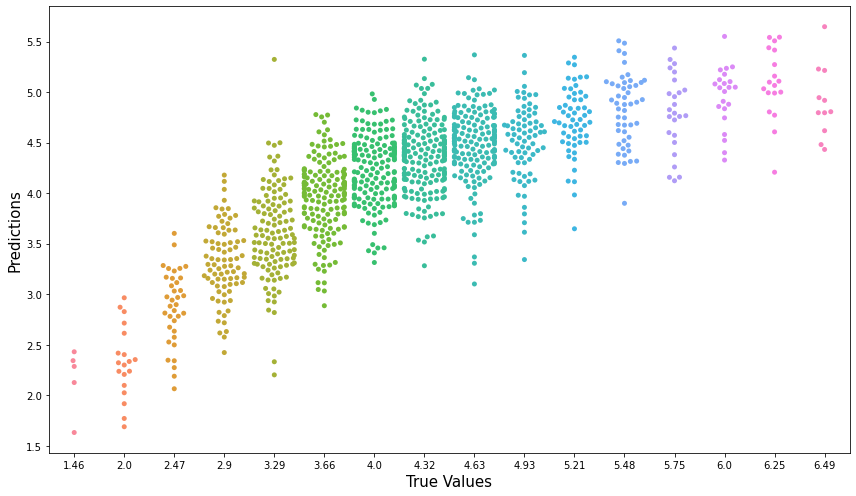

In [188]:
plt.figure(figsize=(12,7))
y_pred=Final_mod.predict(X_test)
sns.swarmplot(Y_test.round(2), y_pred)
print('\033[1m'+' True Values Vs Predicted Value plot :' +'\033[0m')
plt.xlabel('True Values' , fontsize=15)
plt.ylabel('Predictions', fontsize=15)
plt.tight_layout()

<AxesSubplot:>

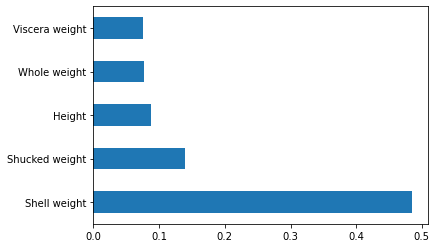

In [192]:
feat_importances = pd.Series(Final_mod.feature_importances_, index=X.columns)
feat_importances = feat_importances.nlargest()
feat_importances.plot(kind='barh')

#### 'Shell weight' is most imporatnt feature for this model.

## Saving model

In [230]:
import joblib
joblib.dump(Final_mod,'Abalone Ring Age Prediction_Final.pkl')

['Abalone Ring Age Prediction_Final.pkl']